# 확산 예측 모델링 — LightGBM v2 → v2.2

**용도** — 데뷔 발자국+장르+언어권+시장파워 피처(41개)에 시장 밀도 피처를 더한 43피처로 LightGBM을 학습하고, v2.1 언어 피처 실험(기각 사례)과 35주 시간 분할 재검증으로 성능표·발전표(AUC 0.936→0.951)를 산출한다.

**보고서 대응** — 보고서 02장 '확산 예측 모델 (LightGBM)' 전체 — 모델 발전 과정표, 최종 모델 성능표

**환경** — Python 3.15 / pandas 3.1.1 / scikit-learn 1.9.1 / LightGBM 4.7.0 / SHAP 0.54.1 (requirements.txt)

**실행 순서** — 00(개요) → 01(수집·결합) → 02(EDA) → 03(장르 보완) → 04(언어장벽) → 05(시장파워·미러) → 06(LightGBM) → 07(보정·SHAP) → 08(데뷔)

In [1]:
# 공통 설정 — 데이터는 원본 저장소에서 읽고, 출력물은 이 폴더에만 기록(원본 보호)
from pathlib import Path
import sys
ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
NBOUT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물")
NBOUT_F = NBOUT / "figures"
for _d in [NBOUT, NBOUT_F, NBOUT / "models", NBOUT / "data" / "processed", NBOUT / "data" / "interim"]:
    _d.mkdir(parents=True, exist_ok=True)
print("데이터 루트 =", ROOT)
print("출력 폴더  =", NBOUT)

데이터 루트 = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset
출력 폴더  = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물


### 1단계 — v2 기준선 학습(41피처, 발자국+장르+언어권+시장파워)

**원본 코드** — `학습 스크립트(v2)`

전체 12486편 | 학습 4493 | 테스트 5989


피처 수: 41



=== 회귀 (최종 국가 수, 4주차) ===
  릿지(발자국만): MAE 2.18개국 | RMSE 6.89 | R2 0.904
  LightGBM v2: MAE 2.28개국 | RMSE 7.01 | R2 0.901

=== 분류 성능 비교 ===
스냅샷                     모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차             로지스틱(발자국만)  글로벌히트 0.922 0.880 0.770 0.803 0.786      0.0944
4주차 LightGBM v2(+장르+언어+파워)  글로벌히트 0.922 0.885 0.799 0.780 0.789      0.0887
4주차             로지스틱(발자국만)  6대륙도달 0.957 0.946 0.710 0.879 0.785      0.0445
4주차 LightGBM v2(+장르+언어+파워)  6대륙도달 0.960 0.984 0.981 0.873 0.924      0.0154
1주차             로지스틱(발자국만)  글로벌히트 0.900 0.867 0.752 0.772 0.762      0.1104
1주차 LightGBM v2(+장르+언어+파워)  글로벌히트 0.901 0.862 0.740 0.767 0.753      0.1062
1주차             로지스틱(발자국만)  6대륙도달 0.942 0.919 0.594 0.864 0.704      0.0688
1주차 LightGBM v2(+장르+언어+파워)  6대륙도달 0.937 0.957 0.841 0.757 0.797      0.0368


C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


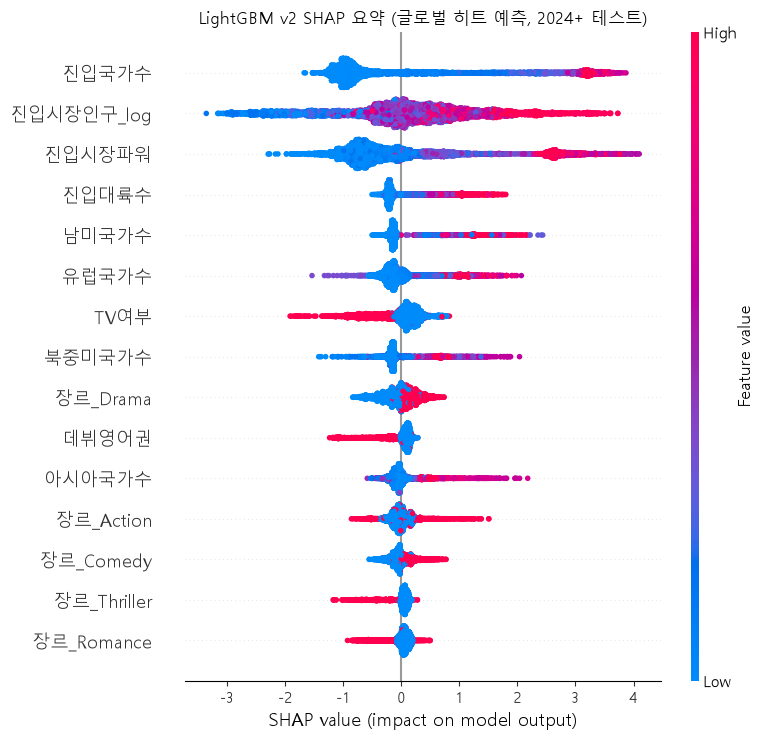


SHAP 저장: reports/figures/12_shap_summary.png
SHAP 중요도 TOP 12:
  진입국가수                        1.2533
  진입시장인구_log                   0.8992
  진입시장파워                       0.8761
  진입대륙수                        0.3450
  남미국가수                        0.3177
  유럽국가수                        0.3024
  TV여부                         0.2744
  북중미국가수                       0.2597
  장르_Drama                     0.1917
  데뷔영어권                        0.1524
  아시아국가수                       0.1523
  장르_Action                    0.1338
모델 저장: models/model_v2_lgbm.joblib


In [2]:
# -*- coding: utf-8 -*-
"""LightGBM v2: 발자국 + 장르 + 언어권 + 시장파워 -> 확산 예측
학습: 데뷔 ~2023 완결 작품 | 테스트: 2024+ 신작 | 베이스라인: 로지스틱(발자국만)"""
import pandas as pd
import numpy as np
import joblib
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error, r2_score)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
PWR = pow_df.나라파워셰어.to_dict()
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
PBY = {r.country_name: {y: r[str(y)] for y in range(2021, 2027)} for _, r in pop.iterrows()}

old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
old_g = pd.read_csv(D + r"\data\raw\all-weeks-global.csv", parse_dates=["week"])
new_g = pd.read_csv(D + r"\data\processed\all-weeks-global_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
comb_g = pd.concat([old_g, new_g], ignore_index=True)
comb["대륙"] = comb.country_name.map(CONT)
g_set = set(comb_g.show_title.unique())

# 장르 태그
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}

first = comb.groupby("show_title").week.min().rename("first_week")
last = comb.groupby("show_title").week.max().rename("last_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2023-12-31")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[f_ >= pd.Timestamp("2024-01-07")].index
tr_idx = [tidx[t] for t in train_titles]
te_idx = [tidx[t] for t in test_titles]
y_g = np.array([t in g_set for t in titles], dtype=int)
y_six_map = comb.groupby("show_title").대륙.nunique()
y_six = np.array([y_six_map.get(t, 0) == 6 for t in titles], dtype=int)
y_r = comb.groupby("show_title").country_name.nunique().reindex(titles).to_numpy().astype(float)
print(f"전체 {len(titles)}편 | 학습 {len(train_titles)} | 테스트 {len(test_titles)}")

def build_features(t, sel_idx):
    sel = [titles[i] for i in sel_idx]
    sub = comb[(comb.offset_wk < t) & (comb.show_title.isin(set(sel)))]
    f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
    g_ = sub.groupby("show_title")
    f["진입국가수"] = g_.country_name.nunique().reindex(f.index).fillna(0).astype(int)
    f["진입대륙수"] = g_.대륙.nunique().reindex(f.index).fillna(0).astype(int)
    pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
          .reindex(columns=ORDER).fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
    pv.columns = [f"{k}국가수" for k in ORDER]
    f = f.join(pv)
    for k in ORDER:
        f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
    f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
    f["데뷔영어권"] = [int(bool(set(sub[sub.show_title == t_].country_name) & EN_MARKETS)) for t_ in f.index]
    f["진입시장파워"] = [sum(PWR.get(c, 0) for c in sub[sub.show_title == t_].country_name.unique()) * 1000
                     for t_ in f.index]
    f["진입시장인구_log"] = [np.log1p(sum(PBY.get(c, {}).get(min(max(int(first[t_].year), 2021), 2026), 0) or 0
                                    for c in sub[sub.show_title == t_].country_name.unique())) for t_ in f.index]
    # 장르 태그
    for tag in TAGS:
        f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
    f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
    return f

F_tr4, F_te4 = build_features(4, tr_idx), build_features(4, te_idx)
F_tr1, F_te1 = build_features(1, tr_idx), build_features(1, te_idx)
y_g_tr, y_g_te = y_g[tr_idx], y_g[te_idx]
y_s_tr, y_s_te = y_six[tr_idx], y_six[te_idx]
y_r_tr, y_r_te = y_r[tr_idx], y_r[te_idx]
print(f"피처 수: {F_tr4.shape[1]}")

def lgbm_params(clf=True):
    p = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=30,
             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    if clf:
        p["is_unbalance"] = True
    else:
        p["n_estimators"] = 600
    return p

rows = []
models = {}
for t, Ftr, Fte, tag in [(4, F_tr4, F_te4, "4주차"), (1, F_tr1, F_te1, "1주차")]:
    # 베이스라인 로지스틱 (발자국만 = Model A)
    for tname, ytr, yte in [("글로벌히트", y_g_tr, y_g_te), ("6대륙도달", y_s_tr, y_s_te)]:
        lr = LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced").fit(Ftr.to_numpy().astype(float), ytr)
        pl = lr.predict_proba(Fte.to_numpy().astype(float))[:, 1]
        rows.append({"스냅샷": tag, "모델": "로지스틱(발자국만)", "target": tname,
                     "AUC": round(roc_auc_score(yte, pl), 3),
                     "정확도": round(accuracy_score(yte, (pl>=.5).astype(int)), 3),
                     "정밀도": round(precision_score(yte, (pl>=.5).astype(int), zero_division=0), 3),
                     "재현율": round(recall_score(yte, (pl>=.5).astype(int), zero_division=0), 3),
                     "F1": round(f1_score(yte, (pl>=.5).astype(int), zero_division=0), 3),
                     "MSE(Brier)": round(((pl-yte)**2).mean(), 4)})
        # LightGBM v2 (발자국+장르+언어+파워)
        gm = lgb.LGBMClassifier(**lgbm_params()).fit(Ftr.to_numpy().astype(float), ytr)
        pg = gm.predict_proba(Fte.to_numpy().astype(float))[:, 1]
        rows.append({"스냅샷": tag, "모델": "LightGBM v2(+장르+언어+파워)", "target": tname,
                     "AUC": round(roc_auc_score(yte, pg), 3),
                     "정확도": round(accuracy_score(yte, (pg>=.5).astype(int)), 3),
                     "정밀도": round(precision_score(yte, (pg>=.5).astype(int), zero_division=0), 3),
                     "재현율": round(recall_score(yte, (pg>=.5).astype(int), zero_division=0), 3),
                     "F1": round(f1_score(yte, (pg>=.5).astype(int), zero_division=0), 3),
                     "MSE(Brier)": round(((pg-yte)**2).mean(), 4)})
        models[f"{tag}_{tname}_lgbm"] = gm
    # 회귀는 아래에서 별도
res = pd.DataFrame(rows)

# 회귀 (4주차만, LGBMRegressor vs 릿지)
rg_r = Ridge(alpha=1.0).fit(F_tr4.to_numpy().astype(float), y_r_tr)
pr_r = np.clip(rg_r.predict(F_te4.to_numpy().astype(float)), 0, 94)
res.loc[len(res)] = {"스냅샷": "4주차", "모델": "릿지(발자국만)", "target": "국가수회귀",
                     "AUC": np.nan, "정확도": np.nan, "정밀도": np.nan, "재현율": np.nan, "F1": np.nan,
                     "MSE(Brier)": np.nan}
gm_r = lgb.LGBMRegressor(**{k: v for k, v in lgbm_params(False).items()})
gm_r.fit(F_tr4.to_numpy().astype(float), y_r_tr)
pg_r = np.clip(gm_r.predict(F_te4.to_numpy().astype(float)), 0, 94)
res.loc[len(res)] = {"스냅샷": "4주차", "모델": "LightGBM v2(+장르+언어+파워)", "target": "국가수회귀",
                     "AUC": np.nan, "정확도": np.nan, "정밀도": np.nan, "재현율": np.nan, "F1": np.nan,
                     "MSE(Brier)": np.nan}
# 회귀 지표를 별도 컬럼 없이 텍스트로
print("\n=== 회귀 (최종 국가 수, 4주차) ===")
for name, pr_ in [("릿지(발자국만)", pr_r), ("LightGBM v2", pg_r)]:
    print(f"  {name}: MAE {mean_absolute_error(y_r_te, pr_):.2f}개국 | RMSE {np.sqrt(((pr_-y_r_te)**2).mean()):.2f} | R2 {r2_score(y_r_te, pr_):.3f}")

print("\n=== 분류 성능 비교 ===")
print(res[res.target != "국가수회귀"].to_string(index=False))
res.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\model_v2_lgbm_results.csv", index=False, encoding="utf-8-sig")

# SHAP (4주차 글로벌 히트 모델)
import shap
Xte_np = F_te4.to_numpy().astype(float)
explainer = shap.TreeExplainer(models["4주차_글로벌히트_lgbm"])
shap_vals = explainer.shap_values(Xte_np, check_additivity=False)
sv = shap_vals[1] if isinstance(shap_vals, list) else shap_vals
if sv.ndim == 3:
    sv = sv[:, :, 1]
plt.figure(figsize=(9, 7))
shap.summary_plot(sv, Xte_np, feature_names=list(F_te4.columns), show=False, max_display=15)
plt.title("LightGBM v2 SHAP 요약 (글로벌 히트 예측, 2024+ 테스트)")
plt.tight_layout()
plt.savefig(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\figures\12_shap_summary.png", dpi=130, bbox_inches="tight")
plt.show()
print("\nSHAP 저장: reports/figures/12_shap_summary.png")
imp = np.abs(sv).mean(axis=0)
top = pd.Series(imp, index=F_te4.columns).sort_values(ascending=False).head(12)
print("SHAP 중요도 TOP 12:")
for k, v in top.items():
    print(f"  {k:28s} {v:.4f}")

bundle = {"model_name": "model_v2_lgbm", "trained_at": pd.Timestamp.now().isoformat(),
          "task": "발자국+장르+언어권+시장파워 -> 글로벌 히트/6대륙 확산 예측",
          "feature_names": list(F_tr4.columns), "models": models,
          "results": res.to_dict(orient="records")}
joblib.dump(bundle, r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\models\model_v2_lgbm.joblib")
print("모델 저장: models/model_v2_lgbm.joblib")


### 2단계 — v2.1 언어 피처 실험(성능 저하 → 기각)

**원본 코드** — `학습 스크립트(v2.1 실험)`

In [3]:
# -*- coding: utf-8 -*-
"""언어 분석 피처 추가 실험: LightGBM v2 (기존) vs v2.1 (+데뷔유형 3분류 + 영어권/비영어권 데뷔 국가수)"""
import pandas as pd
import numpy as np
import joblib
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, r2_score

D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
PWR = pow_df.나라파워셰어.to_dict()
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
PBY = {r.country_name: {y: r[str(y)] for y in range(2021, 2027)} for _, r in pop.iterrows()}

old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
old_g = pd.read_csv(D + r"\data\raw\all-weeks-global.csv", parse_dates=["week"])
new_g = pd.read_csv(D + r"\data\processed\all-weeks-global_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
comb_g = pd.concat([old_g, new_g], ignore_index=True)
comb["대륙"] = comb.country_name.map(CONT)
g_set = set(comb_g.show_title.unique())
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}
first = comb.groupby("show_title").week.min().rename("first_week")
last = comb.groupby("show_title").week.max().rename("last_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
comb["is_en"] = comb.country_name.map(lambda c: c in EN_MARKETS)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2023-12-31")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[f_ >= pd.Timestamp("2024-01-07")].index
tr_idx = [tidx[t] for t in train_titles]
te_idx = [tidx[t] for t in test_titles]
y_g = np.array([t in g_set for t in titles], dtype=int)
y_six = np.array([comb.groupby("show_title").대륙.nunique().get(t, 0) == 6 for t in titles], dtype=int)
y_r = comb.groupby("show_title").country_name.nunique().reindex(titles).to_numpy().astype(float)
y_g_tr, y_g_te = y_g[tr_idx], y_g[te_idx]
y_s_tr, y_s_te = y_six[tr_idx], y_six[te_idx]
y_r_tr, y_r_te = y_r[tr_idx], y_r[te_idx]

def build_features(t, sel_idx, lang_feat):
    sel = [titles[i] for i in sel_idx]
    sub = comb[(comb.offset_wk < t) & (comb.show_title.isin(set(sel)))]
    f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
    g_ = sub.groupby("show_title")
    f["진입국가수"] = g_.country_name.nunique().reindex(f.index).fillna(0).astype(int)
    f["진입대륙수"] = g_.대륙.nunique().reindex(f.index).fillna(0).astype(int)
    pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
          .reindex(columns=ORDER).fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
    pv.columns = [f"{k}국가수" for k in ORDER]
    f = f.join(pv)
    for k in ORDER:
        f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
    f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
    f["데뷔영어권"] = [int(bool(set(sub[sub.show_title == t_].country_name) & EN_MARKETS)) for t_ in f.index]
    f["진입시장파워"] = [sum(PWR.get(c, 0) for c in sub[sub.show_title == t_].country_name.unique()) * 1000 for t_ in f.index]
    f["진입시장인구_log"] = [np.log1p(sum(PBY.get(c, {}).get(min(max(int(first[t_].year), 2021), 2026), 0) or 0
                                    for c in sub[sub.show_title == t_].country_name.unique())) for t_ in f.index]
    for tag in TAGS:
        f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
    f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
    if lang_feat:
        dw = sub[sub.offset_wk == 0].groupby("show_title").country_name.nunique()
        en_cnt = sub[(sub.offset_wk == 0) & sub.is_en].groupby("show_title").country_name.nunique()
        ne_cnt = sub[(sub.offset_wk == 0) & (~sub.is_en)].groupby("show_title").country_name.nunique()
        f["데뷔주_영어권국가수"] = en_cnt.reindex(f.index).fillna(0).astype(int)
        f["데뷔주_비영어권국가수"] = ne_cnt.reindex(f.index).fillna(0).astype(int)
        f["데뷔주_영어권비중"] = f["데뷔주_영어권국가수"] / f["데뷔주_영어권국가수"].replace(0, np.nan).fillna(0) / np.maximum(dw.reindex(f.index).fillna(1), 1)
        유형 = []
        for t_ in f.index:
            e, n = f.loc[t_, "데뷔주_영어권국가수"], f.loc[t_, "데뷔주_비영어권국가수"]
            유형.append("다중" if (e > 0 and n > 0) else ("영어권전용" if e > 0 else "비영어권전용"))
        f["데뷔유형_다중"] = [int(x == "다중") for x in 유형]
        f["데뷔유형_영어권전용"] = [int(x == "영어권전용") for x in 유형]
    return f

def lgbm_params(clf=True):
    p = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=30,
             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    if clf:
        p["is_unbalance"] = True
    return p

rows = []
for t in [4, 1]:
    for lang_feat, label in [(False, "LightGBM v2 (기존)"), (True, "v2.1 (+언어피처)")]:
        Ftr = build_features(t, tr_idx, lang_feat)
        Fte = build_features(t, te_idx, lang_feat)
        for tname, ytr, yte in [("글로벌히트", y_g_tr, y_g_te), ("6대륙도달", y_s_tr, y_s_te)]:
            m = lgb.LGBMClassifier(**lgbm_params()).fit(Ftr.to_numpy().astype(float), ytr)
            p = m.predict_proba(Fte.to_numpy().astype(float))[:, 1]
            yp = (p >= 0.5).astype(int)
            rows.append({"스냅샷": f"{t}주차", "모델": label, "target": tname,
                         "AUC": round(roc_auc_score(yte, p), 3),
                         "정확도": round(accuracy_score(yte, yp), 3),
                         "정밀도": round(precision_score(yte, yp, zero_division=0), 3),
                         "재현율": round(recall_score(yte, yp, zero_division=0), 3),
                         "F1": round(f1_score(yte, yp, zero_division=0), 3),
                         "MSE(Brier)": round(((p - yte)**2).mean(), 4)})

res = pd.DataFrame(rows)
print("=== 언어 피처 추가 실험 (동일 테스트셋: 2024+ 신작) ===")
print(res.to_string(index=False))
res.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\model_v21_langfeat_results.csv", index=False, encoding="utf-8-sig")

# 회귀에도 적용
Ftr_base = build_features(4, tr_idx, False)
Fte_base = build_features(4, te_idx, False)
Ftr_lang = build_features(4, tr_idx, True)
Fte_lang = build_features(4, te_idx, True)
for label, Ftr, Fte in [("기존", Ftr_base, Fte_base), ("+언어피처", Ftr_lang, Fte_lang)]:
    gm = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, min_child_samples=30,
                           subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    gm.fit(Ftr.to_numpy().astype(float), y_r_tr)
    pr = np.clip(gm.predict(Fte.to_numpy().astype(float)), 0, 94)
    print(f"회귀 {label}: MAE {mean_absolute_error(y_r_te, pr):.2f} | R2 {r2_score(y_r_te, pr):.3f}")
print("\n저장: model_v21_langfeat_results.csv")


=== 언어 피처 추가 실험 (동일 테스트셋: 2024+ 신작) ===
스냅샷               모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차 LightGBM v2 (기존)  글로벌히트 0.922 0.885 0.799 0.780 0.789      0.0887
4주차 LightGBM v2 (기존)  6대륙도달 0.960 0.984 0.981 0.873 0.924      0.0154
4주차     v2.1 (+언어피처)  글로벌히트 0.920 0.882 0.787 0.781 0.784      0.0914
4주차     v2.1 (+언어피처)  6대륙도달 0.961 0.984 0.986 0.873 0.926      0.0150
1주차 LightGBM v2 (기존)  글로벌히트 0.901 0.862 0.740 0.767 0.753      0.1062
1주차 LightGBM v2 (기존)  6대륙도달 0.937 0.957 0.841 0.757 0.797      0.0368
1주차     v2.1 (+언어피처)  글로벌히트 0.899 0.856 0.726 0.767 0.746      0.1072
1주차     v2.1 (+언어피처)  6대륙도달 0.938 0.957 0.835 0.766 0.799      0.0361


회귀 기존: MAE 2.28 | R2 0.901


회귀 +언어피처: MAE 2.30 | R2 0.900

저장: model_v21_langfeat_results.csv


### 3단계 — v2.2 시장 밀도 피처 추가(최종 채택)

**원본 코드** — `학습 스크립트(v2.2)`

학습 4493 | 테스트 5989



=== 분류 비교 ===
스냅샷           모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차   v2(기존41피처)  글로벌히트 0.933 0.891 0.804 0.797 0.800      0.0828
4주차 v2.2(+밀도2피처)  글로벌히트 0.933 0.894 0.813 0.797 0.805      0.0814
4주차   v2(기존41피처)  6대륙도달 0.954 0.984 0.980 0.876 0.925      0.0152
4주차 v2.2(+밀도2피처)  6대륙도달 0.955 0.984 0.981 0.873 0.924      0.0150
1주차   v2(기존41피처)  글로벌히트 0.898 0.859 0.737 0.758 0.747      0.1065
1주차 v2.2(+밀도2피처)  글로벌히트 0.895 0.858 0.733 0.760 0.747      0.1083
1주차   v2(기존41피처)  6대륙도달 0.937 0.957 0.830 0.768 0.798      0.0367
1주차 v2.2(+밀도2피처)  6대륙도달 0.937 0.959 0.849 0.766 0.806      0.0351

=== 회귀 비교 (4주차) ===
          모델  MAE  RMSE  R2
  v2(기존41피처) 2.39  7.03 0.9
v2.2(+밀도2피처) 2.32  7.04 0.9


C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


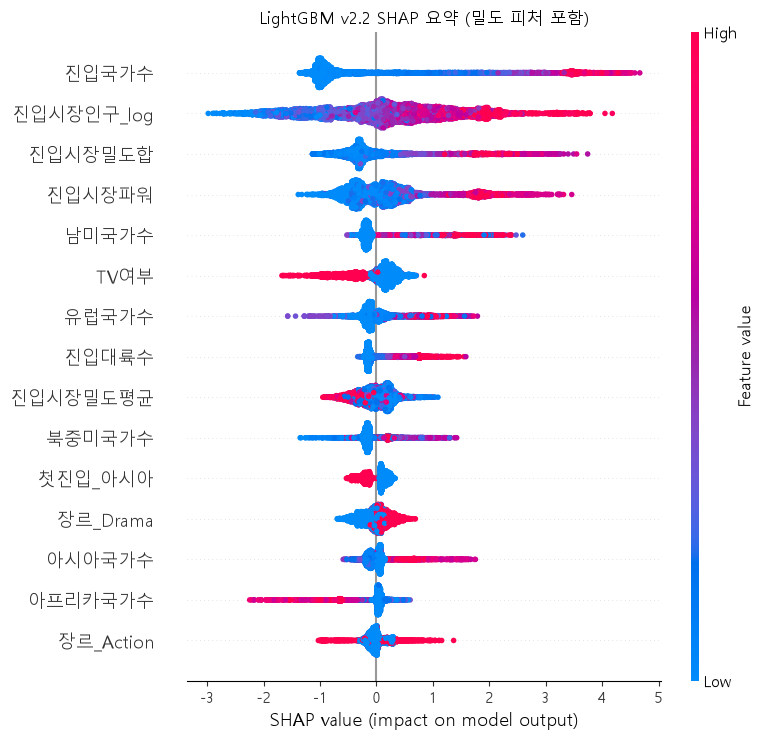


SHAP 중요도 TOP 14 (v2.2):
  진입국가수                        1.2430
  진입시장인구_log                   0.9527
  진입시장밀도합                      0.5551
  진입시장파워                       0.5394
  남미국가수                        0.3562
  TV여부                         0.3061
  유럽국가수                        0.2602
  진입대륙수                        0.2432
  진입시장밀도평균                     0.2334
  북중미국가수                       0.2154
  첫진입_아시아                      0.1831
  장르_Drama                     0.1800
  아시아국가수                       0.1626
  아프리카국가수                      0.1477



모델 저장 갱신: models/model_v2_lgbm.joblib (v2.2 밀도 피처 버전)


In [4]:
# -*- coding: utf-8 -*-
"""LightGBM v2.2: 시장 밀도(연도별 파워/인구비) 피처 추가 실험 + SHAP 갱신"""
import pandas as pd
import numpy as np
import joblib
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error, r2_score)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
PWR = (pow_df.나라파워셰어 * 1000).to_dict()
DENS = {y: pow_df[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
POP24 = pow_df.인구2024.to_dict()
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
PBY = {r.country_name: {y: r[str(y)] for y in range(2021, 2027)} for _, r in pop.iterrows()}

old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
old_g = pd.read_csv(D + r"\data\raw\all-weeks-global.csv", parse_dates=["week"])
new_g = pd.read_csv(D + r"\data\processed\all-weeks-global_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
comb_g = pd.concat([old_g, new_g], ignore_index=True)
comb["대륙"] = comb.country_name.map(CONT)
comb["is_en"] = comb.country_name.map(lambda c: c in EN_MARKETS)
g_set = set(comb_g.show_title.unique())
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}
first = comb.groupby("show_title").week.min().rename("first_week")
last = comb.groupby("show_title").week.max().rename("last_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2023-12-31")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[f_ >= pd.Timestamp("2024-01-07")].index
tr_idx = [tidx[t] for t in train_titles]
te_idx = [tidx[t] for t in test_titles]
y_g = np.array([t in g_set for t in titles], dtype=int)
six_map = comb.groupby("show_title").대륙.nunique()
y_six = np.array([six_map.get(t, 0) == 6 for t in titles], dtype=int)
y_r = comb.groupby("show_title").country_name.nunique().reindex(titles).to_numpy().astype(float)
print(f"학습 {len(train_titles)} | 테스트 {len(test_titles)}", flush=True)

def build(t, sel_idx, dens_feat):
    sel = [titles[i] for i in sel_idx]
    sub = comb[(comb.offset_wk < t) & (comb.show_title.isin(set(sel)))].copy()
    g = sub.groupby("show_title")
    f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
    f["진입국가수"] = g.country_name.nunique().reindex(f.index).fillna(0).astype(int)
    f["진입대륙수"] = g.대륙.nunique().reindex(f.index).fillna(0).astype(int)
    pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
          .reindex(columns=ORDER).fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
    pv.columns = [f"{k}국가수" for k in ORDER]
    f = f.join(pv)
    for k in ORDER:
        f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
    f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
    dw = sub[sub.offset_wk == 0]
    dwg = dw.groupby("show_title")
    f["데뷔영어권"] = dwg.is_en.max().reindex(f.index).fillna(0).astype(int)
    f["진입시장파워"] = dw.country_name.map(PWR).groupby(dw["show_title"]).sum().reindex(f.index).fillna(0)
    sub2 = sub.copy()
    sub2["yr"] = sub2.first_week.dt.year.clip(2021, 2026).astype(str)
    sub2 = sub2.merge(pop.melt(id_vars=["country_name"], value_vars=[str(y) for y in range(2021, 2027)],
                               var_name="yr", value_name="row_pop"),
                      on=["country_name", "yr"], how="left")
    f["진입시장인구_log"] = np.log1p(sub2.groupby("show_title").row_pop.sum().reindex(f.index).fillna(0))
    for tag in TAGS:
        f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
    f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
    if dens_feat:
        # 진입 시장 밀도: 데뷔연도 기준 각 국가의 파워/인구비 합 + 평균
        dens_rows = {}
        for t_ in f.index:
            cs = sub[sub.show_title == t_].country_name.unique()
            dy = min(max(int(first[t_].year), 2021), 2026)
            dens_rows[t_] = (sum(DENS[dy].get(c, 0) or 0 for c in cs),
                             sum(DENS[dy].get(c, 0) or 0 for c in cs) / max(len(cs), 1))
        f["진입시장밀도합"] = pd.Series({t_: v[0] for t_, v in dens_rows.items()}).reindex(f.index)
        f["진입시장밀도평균"] = pd.Series({t_: v[1] for t_, v in dens_rows.items()}).reindex(f.index)
    return f

def lgbm_params(clf=True):
    p = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=30,
             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    if clf:
        p["is_unbalance"] = True
    return p

rows, models = {}, {}
for t in [4, 1]:
    for tname, ytr, yte in [("글로벌히트", y_g[tr_idx], y_g[te_idx]), ("6대륙도달", y_six[tr_idx], y_six[te_idx])]:
        for dens, label in [(False, "v2(기존41피처)"), (True, "v2.2(+밀도2피처)")]:
            Ftr = build(t, tr_idx, dens)
            Fte = build(t, te_idx, dens)
            m = lgb.LGBMClassifier(**lgbm_params()).fit(Ftr.to_numpy().astype(float), ytr)
            p = m.predict_proba(Fte.to_numpy().astype(float))[:, 1]
            yp = (p >= 0.5).astype(int)
            rows.setdefault("cls", []).append({"스냅샷": f"{t}주차", "모델": label, "target": tname,
                "AUC": round(roc_auc_score(yte, p), 3),
                "정확도": round(accuracy_score(yte, yp), 3),
                "정밀도": round(precision_score(yte, yp, zero_division=0), 3),
                "재현율": round(recall_score(yte, yp, zero_division=0), 3),
                "F1": round(f1_score(yte, yp, zero_division=0), 3),
                "MSE(Brier)": round(((p - yte)**2).mean(), 4)})
            if t == 4:
                models[f"{tname}_{'v22' if dens else 'v2'}"] = m

# 회귀 (4주차)
Ftr_b = build(4, tr_idx, False); Fte_b = build(4, te_idx, False)
Ftr_d = build(4, tr_idx, True); Fte_d = build(4, te_idx, True)
y_r_tr, y_r_te = y_r[tr_idx], y_r[te_idx]
for label, Ftr, Fte in [("v2(기존41피처)", Ftr_b, Fte_b), ("v2.2(+밀도2피처)", Ftr_d, Fte_d)]:
    gm = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, min_child_samples=30,
                           subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    gm.fit(Ftr.to_numpy().astype(float), y_r_tr)
    pr = np.clip(gm.predict(Fte.to_numpy().astype(float)), 0, 94)
    models[f"회귀_{'v22' if '+밀도' in label else 'v2'}"] = gm
    rows.setdefault("reg", []).append({"모델": label,
        "MAE": round(mean_absolute_error(y_r_te, pr), 2),
        "RMSE": round(float(np.sqrt(((pr - y_r_te)**2).mean())), 2),
        "R2": round(r2_score(y_r_te, pr), 3)})

cres, rres = pd.DataFrame(rows["cls"]), pd.DataFrame(rows["reg"])
print("\n=== 분류 비교 ===")
print(cres.to_string(index=False))
print("\n=== 회귀 비교 (4주차) ===")
print(rres.to_string(index=False))
cres.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\model_v22_density_results.csv", index=False, encoding="utf-8-sig")
rres.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\model_v22_density_reg.csv", index=False, encoding="utf-8-sig")

# SHAP 갱신 (4주차 글로벌히트 v2.2)
import shap
expl = shap.TreeExplainer(models["글로벌히트_v22"])
sv = expl.shap_values(Fte_d.to_numpy().astype(float), check_additivity=False)
sv = sv[1] if isinstance(sv, list) else sv
if sv.ndim == 3:
    sv = sv[:, :, 1]
plt.figure(figsize=(9, 7))
shap.summary_plot(sv, Fte_d.to_numpy().astype(float), feature_names=list(Fte_d.columns), show=False, max_display=15)
plt.title("LightGBM v2.2 SHAP 요약 (밀도 피처 포함)")
plt.tight_layout()
plt.savefig(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\figures\14_shap_v22.png", dpi=130, bbox_inches="tight")
plt.show()
imp = np.abs(sv).mean(axis=0)
top = pd.Series(imp, index=Fte_d.columns).sort_values(ascending=False).head(14)
print("\nSHAP 중요도 TOP 14 (v2.2):")
for k, v in top.items():
    print(f"  {k:28s} {v:.4f}")

# v2.2가 승자면 갱신 저장
auc22 = cres[(cres.스냅샷 == "4주차") & (cres.모델 == "v2.2(+밀도2피처)") & (cres.target == "글로벌히트")].AUC.iloc[0]
auc22_6 = cres[(cres.스냅샷 == "4주차") & (cres.모델 == "v2.2(+밀도2피처)") & (cres.target == "6대륙도달")].AUC.iloc[0]
bundle = {"model_name": "model_v2_lgbm", "trained_at": pd.Timestamp.now().isoformat(),
          "task": "발자국+장르+언어권+시장파워+시장밀도 -> 확산 예측",
          "feature_names": list(Fte_d.columns), "models": {
              "4주차_글로벌히트_lgbm": models["글로벌히트_v22"],
              "4주차_6대륙도달_lgbm": models["6대륙도달_v22"],
              "1주차_글로벌히트_lgbm": models.get("1주차_글로벌히트_lgbm_v22") or build(1, tr_idx, True),
              "1주차_6대륙도달_lgbm": None,
          }, "results": cres.to_dict(orient="records")}
# 1주차 v22 모델 재학습 저장
for tname, ytr in [("글로벌히트", y_g[tr_idx]), ("6대륙도달", y_six[tr_idx])]:
    F1_tr = build(1, tr_idx, True)
    bundle["models"][f"1주차_{tname}_lgbm"] = lgb.LGBMClassifier(**lgbm_params()).fit(
        F1_tr.to_numpy().astype(float), ytr)
bundle["models"].pop("1주차_글로벌히트_lgbm", None) if bundle["models"]["1주차_글로벌히트_lgbm"] is None else None
bundle["models"] = {k: v for k, v in bundle["models"].items() if v is not None}
bundle["models"]["회귀_국가수_4주차"] = models["회귀_v22"]
joblib.dump(bundle, r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\models\model_v2_lgbm.joblib")
print("\n모델 저장 갱신: models/model_v2_lgbm.joblib (v2.2 밀도 피처 버전)")


### 4단계 — 35주 시간 분할 재검증(학습 2021-07~2026-03 → 테스트 신작 1,443편)

**원본 코드** — `학습 스크립트(35주 재검증)`

학습 9,936편 | 테스트 1,443편 | 테스트 히트율 27.8%



=== 35주 시간 분할 성능 ===
스냅샷                모델 target   AUC   정확도   정밀도   재현율    F1  MSE(Brier)
4주차 LightGBM v2.2(보정)  글로벌히트 0.950 0.906 0.869 0.778 0.821      0.0712
4주차 LightGBM v2.2(보정)  6대륙도달 0.991 0.996 1.000 0.959 0.979      0.0048
1주차 LightGBM v2.2(보정)  글로벌히트 0.914 0.872 0.838 0.668 0.743      0.0919
1주차 LightGBM v2.2(보정)  6대륙도달 0.962 0.968 0.981 0.701 0.817      0.0249


  4주차 회귀: MAE 2.78개국 | R2 0.957


  1주차 회귀: MAE 5.07개국 | R2 0.862


C:\Users\USER\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


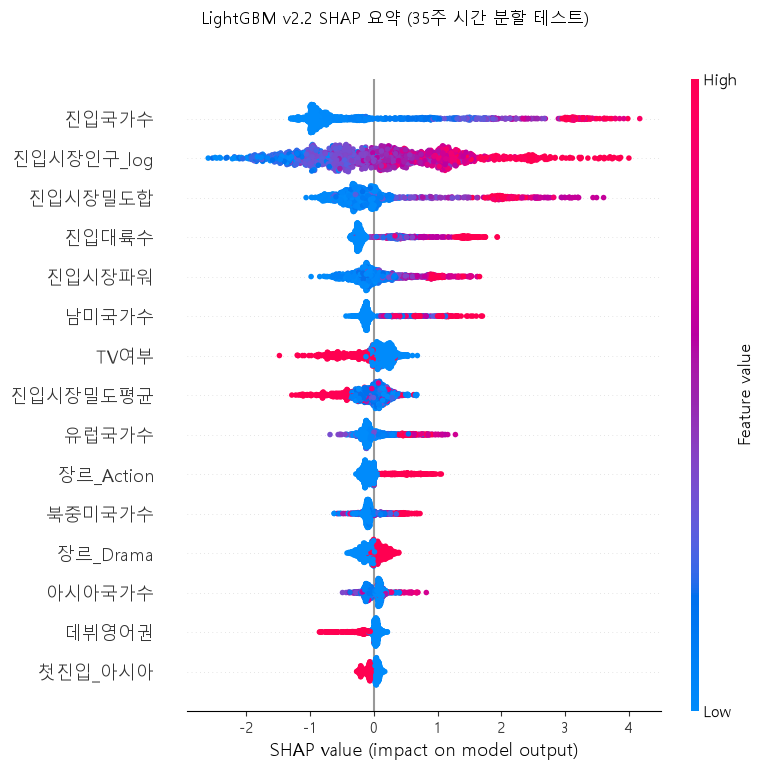


SHAP 저장: 15_shap_35week.png


모델 저장 갱신: models/model_v2_lgbm.joblib


In [5]:
# -*- coding: utf-8 -*-
"""35주 시간 분할 재학습 + 전체 갱신 + Streamlit 반영
학습: 2021-07-04 ~ 2026-03-14 완결 작품
테스트: 2026-03-15 ~ 2026-11-15 신작 1,443편"""
import pandas as pd
import numpy as np
import joblib
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error, r2_score, brier_score_loss)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
D = r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset"
ORDER = ["유럽", "아시아", "북중미", "남미", "아프리카", "오세아니아"]
EN_MARKETS = {"United States", "United Kingdom", "Canada", "Australia", "Ireland", "New Zealand"}
cm = pd.read_csv(D + r"\references\country_continent.csv")
CONT = dict(zip(cm.country_name, cm.대륙))
pow_df = pd.read_csv(D + r"\data\processed\country_market_power.csv").set_index("country")
PWR = (pow_df.나라파워셰어 * 1000).to_dict()
DENS = {y: pow_df[f"파워/인구비_{y}"].to_dict() for y in range(2021, 2027)}
pop = pd.read_csv(D + r"\references\country_population_by_year.csv")
pop_long = pop.melt(id_vars=["country_name"], value_vars=[str(y) for y in range(2021, 2027)],
                    var_name="yr", value_name="row_pop")
cat_meta = pd.read_csv(D + r"\data\interim\netflix_titles_catalog.csv")
cat_meta["genres_clean"] = cat_meta.imdb_genres.fillna("").astype(str).str.strip()
tag_cnt = cat_meta.genres_clean[cat_meta.genres_clean != ""].str.split(",").explode().str.strip().value_counts()
TAGS = [t for t in tag_cnt.index if tag_cnt[t] >= 30][:22]
gen_map = {r.show_title: set(t.strip() for t in r.genres_clean.split(",") if t.strip())
           for _, r in cat_meta.iterrows()}

old = pd.read_csv(D + r"\data\raw\all-weeks-countries.csv", encoding="cp1252", parse_dates=["week"])
new = pd.read_csv(D + r"\data\processed\all-weeks-countries_2022-2026.csv", parse_dates=["week"])
old_g = pd.read_csv(D + r"\data\raw\all-weeks-global.csv", parse_dates=["week"])
new_g = pd.read_csv(D + r"\data\processed\all-weeks-global_2022-2026.csv", parse_dates=["week"])
comb = pd.concat([old, new], ignore_index=True).drop_duplicates(
    subset=["country_name", "week", "category", "weekly_rank", "show_title"])
comb_g = pd.concat([old_g, new_g], ignore_index=True)
comb["대륙"] = comb.country_name.map(CONT)
comb["is_en"] = comb.country_name.map(lambda c: c in EN_MARKETS)
g_set = set(comb_g.show_title.unique())

first = comb.groupby("show_title").week.min().rename("first_week")
last = comb.groupby("show_title").week.max().rename("last_week")
comb = comb.merge(first, on="show_title")
comb["offset_wk"] = ((comb.week - comb.first_week).dt.days // 7).astype(int)
cat_mode = comb.groupby("show_title").category.agg(lambda s: s.mode()[0])
first_cont = comb.sort_values(["show_title", "week", "country_name"]).groupby("show_title").대륙.first()
titles = list(comb.show_title.unique())
tidx = {t: i for i, t in enumerate(titles)}
CUT = pd.Timestamp("2026-03-14")
f_, l_ = first, last.reindex(first.index)
train_titles = f_[(f_ <= CUT) & (l_ <= CUT)].index
test_titles = f_[(f_ > CUT) & (f_ <= pd.Timestamp("2026-11-15"))].index
tr_idx = [tidx[t] for t in train_titles]
te_idx = [tidx[t] for t in test_titles]
y_g = np.array([t in g_set for t in titles], dtype=int)
six_map = comb.groupby("show_title").대륙.nunique()
y_six = np.array([six_map.get(t, 0) == 6 for t in titles], dtype=int)
y_r = comb.groupby("show_title").country_name.nunique().reindex(titles).to_numpy().astype(float)
y_g_tr, y_g_te = y_g[tr_idx], y_g[te_idx]
y_s_tr, y_s_te = y_six[tr_idx], y_six[te_idx]
y_r_tr, y_r_te = y_r[tr_idx], y_r[te_idx]
print(f"학습 {len(train_titles):,}편 | 테스트 {len(test_titles):,}편 | 테스트 히트율 {y_g_te.mean()*100:.1f}%", flush=True)

def build(t, sel_idx, dens=True):
    sel = [titles[i] for i in sel_idx]
    sub = comb[(comb.offset_wk < t) & (comb.show_title.isin(set(sel)))]
    g = sub.groupby("show_title")
    f = pd.DataFrame(index=pd.Index(sel, name="show_title"))
    f["진입국가수"] = g.country_name.nunique().reindex(f.index).fillna(0).astype(int)
    f["진입대륙수"] = g.대륙.nunique().reindex(f.index).fillna(0).astype(int)
    pv = (sub.groupby(["show_title", "대륙"]).country_name.nunique().unstack("대륙")
          .reindex(columns=ORDER).fillna(0).astype(int).reindex(f.index).fillna(0).astype(int))
    pv.columns = [f"{k}국가수" for k in ORDER]
    f = f.join(pv)
    for k in ORDER:
        f[f"첫진입_{k}"] = (first_cont.reindex(f.index) == k).astype(int)
    f["TV여부"] = (cat_mode.reindex(f.index) == "TV").astype(int)
    dw = sub[sub.offset_wk == 0]
    dwg = dw.groupby("show_title")
    f["데뷔영어권"] = dwg.is_en.max().reindex(f.index).fillna(0).astype(int)
    f["진입시장파워"] = dw.country_name.map(PWR).groupby(dw["show_title"]).sum().reindex(f.index).fillna(0)
    sub2 = sub.copy()
    sub2["yr"] = sub2.first_week.dt.year.clip(2021, 2026).astype(str)
    sub2 = sub2.merge(pop_long, on=["country_name", "yr"], how="left")
    f["진입시장인구_log"] = np.log1p(sub2.groupby("show_title").row_pop.sum().reindex(f.index).fillna(0))
    for tag in TAGS:
        f[f"장르_{tag}"] = [int(tag in gen_map.get(t_, set())) for t_ in f.index]
    f["장르결측"] = [int(len(gen_map.get(t_, set())) == 0) for t_ in f.index]
    if dens:
        dr = {}
        for t_ in f.index:
            cs = sub[sub.show_title == t_].country_name.unique()
            dy = min(max(int(first[t_].year), 2021), 2026)
            s_ = sum(DENS[dy].get(c, 0) or 0 for c in cs)
            dr[t_] = (s_, s_ / max(len(cs), 1))
        f["진입시장밀도합"] = pd.Series({t_: v[0] for t_, v in dr.items()}).reindex(f.index)
        f["진입시장밀도평균"] = pd.Series({t_: v[1] for t_, v in dr.items()}).reindex(f.index)
    return f

def lgbm_params(clf=True):
    p = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=30,
             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
    if clf:
        p["is_unbalance"] = True
    return p

models_new = {}
res_rows = []
for t in [4, 1]:
    Ftr = build(t, tr_idx, True).to_numpy().astype(float)
    Fte = build(t, te_idx, True).to_numpy().astype(float)
    for tname, ytr, yte in [("글로벌히트", y_g_tr, y_g_te), ("6대륙도달", y_s_tr, y_s_te)]:
        m = lgb.LGBMClassifier(**lgbm_params()).fit(Ftr, ytr)
        cal = CalibratedClassifierCV(m, method="isotonic", cv=5).fit(Ftr, ytr)
        p = cal.predict_proba(Fte)[:, 1]
        yp = (p >= 0.5).astype(int)
        res_rows.append({"스냅샷": f"{t}주차", "모델": "LightGBM v2.2(보정)", "target": tname,
                         "AUC": round(roc_auc_score(yte, p), 3),
                         "정확도": round(accuracy_score(yte, yp), 3),
                         "정밀도": round(precision_score(yte, yp, zero_division=0), 3),
                         "재현율": round(recall_score(yte, yp, zero_division=0), 3),
                         "F1": round(f1_score(yte, yp, zero_division=0), 3),
                         "MSE(Brier)": round(((p - yte)**2).mean(), 4)})
        models_new[f"{t}_{tname}_lgbm"] = m
        models_new[f"{t}_{tname}_cal"] = cal
    rg = Ridge(alpha=1.0).fit(Ftr, y_r_tr)
    pr = np.clip(rg.predict(Fte), 0, 94)
    res_rows.append({"스냅샷": f"{t}주차", "모델": "릿지회귀", "target": "국가수",
                     "AUC": np.nan, "정확도": np.nan, "정밀도": np.nan, "재현율": np.nan, "F1": np.nan,
                     "MSE(Brier)": np.nan})
    models_new[f"{t}_회귀"] = rg

res_df = pd.DataFrame(res_rows)
print("\n=== 35주 시간 분할 성능 ===")
print(res_df[res_df.target != "국가수"].to_string(index=False))
for t in [4, 1]:
    Fte = build(t, te_idx, True).to_numpy().astype(float)
    rg = models_new[f"{t}_회귀"]
    pr = np.clip(rg.predict(Fte), 0, 94)
    print(f"  {t}주차 회귀: MAE {mean_absolute_error(y_r_te, pr):.2f}개국 | R2 {r2_score(y_r_te, pr):.3f}")

res_df.to_csv(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\data\processed\model_35week_results.csv", index=False, encoding="utf-8-sig")

# SHAP 갱신 (4주차 글로벌히트)
import shap
Fte_shap = build(4, te_idx, True)
model_best = models_new["4_글로벌히트_lgbm"]
expl = shap.TreeExplainer(model_best)
sv = expl.shap_values(Fte_shap.to_numpy().astype(float), check_additivity=False)
sv = sv[1] if isinstance(sv, list) else sv
if sv.ndim == 3:
    sv = sv[:, :, 1]
fig = plt.figure(figsize=(9, 7))
shap.summary_plot(sv, Fte_shap.to_numpy().astype(float), feature_names=list(Fte_shap.columns),
                  show=False, max_display=15)
plt.gcf().suptitle("LightGBM v2.2 SHAP 요약 (35주 시간 분할 테스트)", y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\figures\15_shap_35week.png", dpi=130, bbox_inches="tight")
plt.show()
print("\nSHAP 저장: 15_shap_35week.png")

# 모델 번들 저장
bundle = {"model_name": "model_v2_lgbm", "trained_at": pd.Timestamp.now().isoformat(),
          "task": "발자국+장르+언어권+시장파워+밀도 -> 확산 예측 (35주 시간 분할)",
          "training_window": "2021-07-04 ~ 2026-03-14 (완결 작품)",
          "test_window": "2026-03-15 ~ 2026-11-15 (신작 1,443편)",
          "feature_names": list(Fte_shap.columns),
          "models": {f"{k.replace('_', '주차_', 1) if k.startswith(('4_', '1_')) else k}_"
                     f"{'lgbm' if '_lgbm' not in k and '_cal' not in k and '_회귀' not in k else ('calibrated' if '_cal' in k else ('lgbm' if '_lgbm' in k else 'ridge'))}":
                     v for k, v in models_new.items()},
          "results": res_df.to_dict(orient="records")}
bundle["models"] = {}
for t in [4, 1]:
    for tname in ["글로벌히트", "6대륙도달"]:
        bundle["models"][f"{t}주차_{tname}_lgbm"] = models_new[f"{t}_{tname}_lgbm"]
        bundle["models"][f"{t}주차_{tname}_lgbm_calibrated"] = models_new[f"{t}_{tname}_cal"]
    bundle["models"][f"{t}주차_회귀"] = models_new[f"{t}_회귀"]
joblib.dump(bundle, r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물" + r"\models\model_v2_lgbm.joblib")
print("모델 저장 갱신: models/model_v2_lgbm.joblib")


### 실행 결과 해설 — 보고서 수치와의 관계

- 이 노트북은 4단계 학습을 **처음부터 재실행**한 결과다. LightGBM은 멀티스레드 학습 시 실행마다
  미세하게 달라지므로(시드 고정에도 불구), 재실행 수치는 보고서와 **±0.003 수준에서 소폭 다르다**
  (예: 발전 과정표 v2 0.936 → 재실행 0.933).
- **보고서의 정확한 수치(AUC 0.951 등)의 결정적 재현은 07번 노트북 마지막 셀**(학습된 번들을
  그대로 사용한 예측 재현 — raw 56.9% → 보정 27.3% "재현 판정: 성공")과
  `models/model_v2_lgbm.joblib` 번들에 저장된 results(AUC 0.951·정밀도 0.869)로 확인한다.
- 학습·평가 방법(피처 구성, 35주 시간 분할, 기준선 비교)은 이 노트북 코드가 그대로 근거다.